# nDCG at 5

**이 노트북에서 할 일**

1. 자리 번호마다 다른 무게를 매겨 순위를 값에 넣습니다.
2. 정답 문서 자리만 옮겨 정밀도와 nDCG가 어떻게 갈리는지 봅니다.
3. 개발 분할 15문항의 nDCG@5를 내고 앞 절 두 지표와 나란히 읽습니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 열여섯 번입니다. 색인 한 벌에 한 번, 질문 검색에 열다섯 번입니다.

03절과 같은 방식이라 요청 수도 같습니다.
첫 질문을 따로 검색하지 않고 반복 검색 결과에서 꺼내 씁니다.
답을 쓰는 모델은 이 절에서 부르지 않습니다.

보낼 조각 수는 색인이 59190개 어림이고 질문은 한 번에 스무 개 안팎입니다.
예상 비용은 열여섯 번을 합쳐 0.01달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)의 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 1분 안팎입니다.

**데이터** — 읽는 파일은 네 갈래이고 모두 실습 묶음에 들어 있습니다.

- 말뭉치 `labs/data/rag-corpus/pdf/`의 디지털 PDF 18건과 `labs/data/rag-corpus/manifest.json`
- 평가셋 `labs/part3/ch11-evaluation/data/evaluation-queries.jsonl`
- Ch 9 06절 기록 `labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl`
- Ch 10 08절 기록 `labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl`

이 절은 파일을 쓰지 않습니다. 02·03절과 같은 기준선 색인을 다시 만듭니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 설명합니다.
자리 무게 만들기, nDCG 함수 세 개, 자리만 옮겨 보기, 앞 챕터 기록으로 잴 수 있는 자리입니다.
7~11절은 함께 실행하고 실습 시간에 다시 읽습니다.
6절 색인 만들기는 02·03절과 같은 코드라 실행만 하고 빠르게 넘어갑니다.

**기준 버전** — 고정한 패키지는 다섯 개입니다.

- 쪽 읽기: pypdf 6.1.1
- 색인과 임베딩: langchain-core 1.6.2 · langchain-openai 1.6.0
- 코사인 유사도 계산: numpy 2.5.3
- 키 읽기: python-dotenv 1.2.3

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch11-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

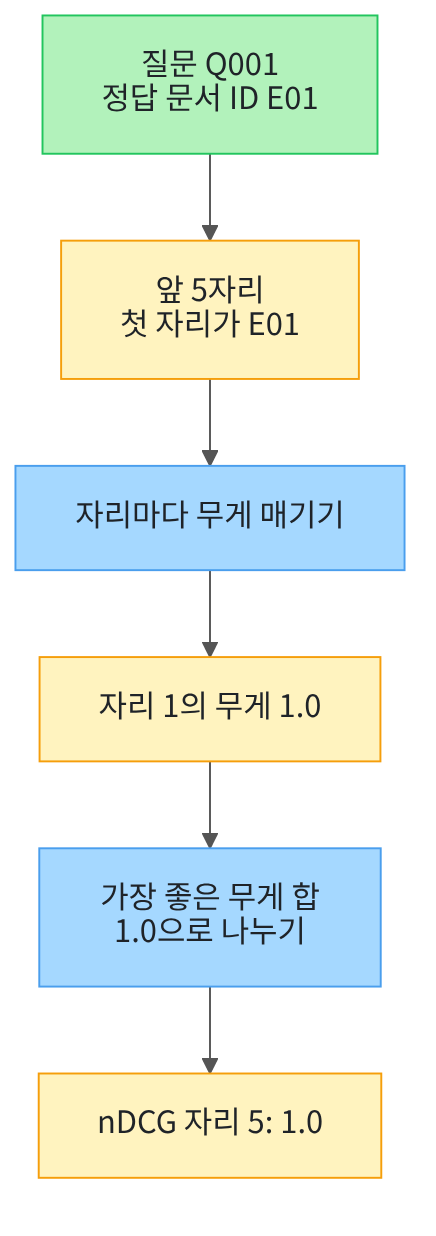

맨 위 초록 상자가 이 절의 입력입니다. 질문 하나와 그 질문의 정답 문서 ID입니다.
그 아래 노란 상자가 03절에서 만든 앞 5자리 목록이고, 파란 상자에서 자리마다 무게를 매깁니다.
맨 아래 두 상자가 이 절의 나누기입니다. 무게 합을 가장 좋은 무게 합으로 나눕니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
02·03절에서 쓴 다섯 개와 같습니다. 이 절도 검색을 직접 하기 때문입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.1.1" "langchain-core==1.6.2" "langchain-openai==1.6.0" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.1.1
langchain-core: 1.6.2
langchain-openai: 1.6.0
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 다섯 줄 가운데 첫 줄은 `pypdf: 6.1.1`입니다.
둘째 줄 `langchain-core: 1.6.2`와 셋째 줄 `langchain-openai: 1.6.0`도 보세요.
넷째 줄 `numpy: 2.5.3`은 색인이 코사인 유사도를 계산할 때 쓰는 패키지입니다.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다. 03절과 같은 패키지 이름에 `math` 한 줄이 늘었습니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 01절 `unique_doc_ids()`·`find_gold_rank()`와 02절 `recall_at()`·`mean_score()`·`make_candidate_list()`를 가져옵니다.
03절 `precision_at()`과 Ch 9 02절 `load_pdf_pages()`도 가져옵니다.

In [2]:
# 평가셋 읽기·로그 계산·임베딩·색인에 쓸 이름을 불러옵니다
import json
import math

from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
# 01~03절과 Ch 9 02절 함수 일곱 개를 도구 파일에서 가져옵니다
from rag_tools import find_gold_rank, load_pdf_pages, make_candidate_list, mean_score
from rag_tools import precision_at, recall_at, unique_doc_ids

**결과 읽기** — 이 셀은 이름을 불러오기만 하므로 출력이 없습니다.
모듈 `math`는 Ch 5 02절에서 제곱근을 낼 때 쓴 그 모듈입니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.
이 셀은 모듈 `os`도 함께 불러옵니다. 다음 셀에서 파일이 있는지 확인할 때 씁니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~03절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 고른 경로에 파일 이름을 이어 붙여 네 갈래 경로를 만듭니다.

In [5]:
# 이 절에서 읽을 파일 네 갈래의 경로를 만듭니다
corpus_path = root_path + "/labs/data/rag-corpus"
manifest_path = corpus_path + "/manifest.json"
dataset_path = root_path + "/labs/part3/ch11-evaluation/data/evaluation-queries.jsonl"
ch09_log_path = root_path + "/labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl"
ch10_log_path = root_path + "/labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl"
print("평가셋 파일이 있는가:", os.path.exists(dataset_path))
print("말뭉치 목록이 있는가:", os.path.exists(manifest_path))
print("Ch 9 기록이 있는가:", os.path.exists(ch09_log_path))
print("Ch 10 기록이 있는가:", os.path.exists(ch10_log_path))

평가셋 파일이 있는가: True
말뭉치 목록이 있는가: True
Ch 9 기록이 있는가: True
Ch 10 기록이 있는가: True


**결과 읽기** — 네 줄 모두 `True`입니다. 02·03절이 읽은 네 갈래와 같습니다.

## 2. 자리마다 무게 주기

03절은 앞 다섯 자리에 정답 문서가 몇 개 있는지 셌습니다.
1번째에 있든 5번째에 있든 값은 같았습니다.
이 절은 자리마다 다른 무게를 매겨 그 차이를 값에 넣습니다.

먼저 평가셋 30줄을 읽고 개발 분할 15문항만 남깁니다. 02·03절과 같은 코드입니다.

In [6]:
# 평가셋 30줄을 읽고 설정을 고를 때 쓰는 개발 분할만 남깁니다(03절 2절과 같은 코드)
with open(dataset_path, encoding="utf-8") as dataset_file:
    dataset_lines = dataset_file.read().splitlines()

queries = []
for line in dataset_lines:
    queries.append(json.loads(line))

dev_queries = []
for query in queries:
    if query["split"] == "dev":
        dev_queries.append(query)
print("평가셋 줄 수:", len(queries))
print("개발 분할 질문 수:", len(dev_queries))
print("첫 질문 번호:", dev_queries[0]["qid"])

평가셋 줄 수: 30
개발 분할 질문 수: 15
첫 질문 번호: Q001


**결과 읽기** — 출력 줄은 `평가셋 줄 수: 30`과 `개발 분할 질문 수: 15`입니다.
셋째 줄 `첫 질문 번호: Q001`은 02·03절에서 후보 목록을 본 그 질문입니다.

무게를 매기려면 자리 번호가 커질수록 작아지는 수가 필요합니다.
그냥 자리 번호로 나누면 뒤 자리가 너무 빨리 작아집니다.
로그2 값은 천천히 커지는 수라 나누는 수로 쓰기에 알맞습니다.

로그2는 2를 몇 번 곱해야 그 수가 되는지 알려 주는 계산입니다.
여덟 명이 둘씩 겨루면 우승자가 나오기까지 세 판이 걸립니다.
그 세 판이 8의 로그2 값입니다.
Ch 5 02절에서 쓴 모듈 `math`에 `log2` 함수가 들어 있습니다.

다음 셀은 작은 수 세 개로 `math.log2`가 무엇을 내놓는지 확인합니다.

In [7]:
# math.log2에 작은 수 세 개를 넣어 어떤 값이 나오는지 봅니다
print("2의 로그2 값:", math.log2(2))
print("4의 로그2 값:", math.log2(4))
print("8의 로그2 값:", math.log2(8))

2의 로그2 값: 1.0
4의 로그2 값: 2.0
8의 로그2 값: 3.0


**결과 읽기** — 출력 줄은 `2의 로그2 값: 1.0`과 `4의 로그2 값: 2.0`과 `8의 로그2 값: 3.0`입니다.
2를 한 번 곱하면 2이고 두 번 곱하면 4이며 세 번 곱하면 8입니다.
수가 두 배로 커져야 로그2 값이 1만큼 늘어납니다.
그래서 자리 번호가 커져도 나누는 수는 천천히 커집니다.

다음 셀은 자리 번호를 받아 그 자리의 무게를 내는 함수입니다.
나누는 수를 `자리 + 1`의 로그2 값으로 두면 자리 1의 무게가 1.0이 됩니다.
자리 1에서 로그2 값이 1.0이기 때문입니다.

In [8]:
# 자리 번호를 받아 그 자리의 무게를 냅니다(자리 1이 가장 크고 뒤로 갈수록 작아집니다)
def rank_weight(rank):
    return 1 / math.log2(rank + 1)

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.
인자 `rank`는 1부터 세는 자리 번호입니다. 01절 `find_gold_rank()`가 내는 자리와 같은 방식입니다.

다음 셀은 자르는 자리 5까지 무게가 얼마인지 표로 봅니다.

In [9]:
# 자르는 자리 5까지 자리마다 무게가 얼마인지 표로 봅니다
cutoff_narrow = 5
print("자리 번호 | 자리 무게")
for position in range(cutoff_narrow):
    rank = position + 1
    weight = round(rank_weight(rank), 3)
    print(rank, "|", weight)

자리 번호 | 자리 무게
1 | 1.0
2 | 0.631
3 | 0.5
4 | 0.431
5 | 0.387


**결과 읽기** — 라벨 줄 `자리 번호 | 자리 무게` 아래 다섯 줄이 있습니다.
첫 줄은 `1 | 1.0`이고 마지막 줄은 `5 | 0.387`입니다.
둘째 줄 `2 | 0.631`과 셋째 줄 `3 | 0.5`에서 무게가 줄어드는 모습을 봅니다.

줄어드는 폭은 뒤로 갈수록 작아집니다.
첫 줄과 둘째 줄의 차이가 넷째 줄과 다섯째 줄의 차이보다 큽니다.
1번째를 2번째로 미루는 일이 4번째를 5번째로 미루는 일보다 값을 많이 깎습니다.

## 3. nDCG 함수 만들기

다음 셀이 이 절의 첫 계산입니다.
앞 자리부터 차례로 보면서 정답 문서를 만날 때마다 그 자리의 무게를 더합니다.
02절 재현율·03절 정밀도와 인자 모양이 같습니다.

In [10]:
# 앞 자리부터 정답 문서를 만날 때마다 그 자리의 무게를 더해 무게 합을 냅니다
def dcg_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    total = 0
    for position in range(len(top_ids)):
        if top_ids[position] in gold_doc_ids:
            total = total + rank_weight(position + 1)
    return total

**결과 읽기** — 이 셀은 함수만 정의하므로 출력이 없습니다.
반복 번호 `position`은 0부터 세므로 1을 더해 자리 번호로 바꿉니다.
정답 문서가 아닌 자리는 더하지 않습니다.

다음 셀은 만점에 해당하는 값을 내는 함수입니다.
정답 문서를 앞자리부터 빈틈없이 놓았을 때의 무게 합입니다.

In [11]:
# 정답 문서를 앞자리부터 빈틈없이 놓았을 때의 무게 합을 냅니다
def ideal_dcg(gold_count, cutoff):
    best_count = gold_count
    if best_count > cutoff:
        best_count = cutoff
    total = 0
    for position in range(best_count):
        total = total + rank_weight(position + 1)
    return total

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
정답 문서 수가 자르는 자리보다 많으면 자리 수만큼만 셉니다.
다 담을 수 없는 정답 문서까지 만점에 넣으면 아무도 만점을 받지 못하기 때문입니다.

다음 셀은 정답 문서 수를 바꿔 가며 만점이 얼마인지 확인합니다.

In [12]:
# 정답 문서 수에 따라 가장 좋은 무게 합이 얼마인지 확인합니다
best_for_one = round(ideal_dcg(1, cutoff_narrow), 3)
best_for_two = round(ideal_dcg(2, cutoff_narrow), 3)
print("정답 문서가 1개일 때 가장 좋은 무게 합:", best_for_one)
print("정답 문서가 2개일 때 가장 좋은 무게 합:", best_for_two)

정답 문서가 1개일 때 가장 좋은 무게 합: 1.0
정답 문서가 2개일 때 가장 좋은 무게 합: 1.631


**결과 읽기** — 첫 줄은 `정답 문서가 1개일 때 가장 좋은 무게 합: 1.0`입니다.
자리 1의 무게 하나뿐이라 1.0입니다.
둘째 줄 `정답 문서가 2개일 때 가장 좋은 무게 합: 1.631`은 자리 1과 자리 2의 무게를 더한 값입니다.

이 평가셋 30문항은 모두 정답 문서가 한 개입니다(01절 7절).
그래서 이 노트북의 지표 계산에서는 만점이 늘 1.0입니다.
정답 문서가 두 개인 값은 함수 동작을 보려고 한 번 확인했습니다.

다음 셀이 이 절의 지표입니다. 무게 합을 만점으로 나눕니다.

In [13]:
# 무게 합을 가장 좋은 무게 합으로 나눠 0에서 1 사이 값으로 맞춥니다
def ndcg_at(doc_ids, gold_doc_ids, cutoff):
    found_score = dcg_at(doc_ids, gold_doc_ids, cutoff)
    best_score = ideal_dcg(len(gold_doc_ids), cutoff)
    return found_score / best_score

**결과 읽기** — 이 셀도 함수만 정의하므로 출력이 없습니다.
인자 모양은 02절 `recall_at()`·03절 `precision_at()`과 같습니다.
중복 제거는 함수 밖에서 먼저 하고 자르기는 함수 안에서 합니다.

## 4. 자리만 옮겨 보기

손으로 만든 목록 세 개로 자리 차이가 어디에 드러나는지 봅니다.
검색 품질이 아니라 계산 방법을 보는 자리입니다.
정답 문서 자리는 01절 `find_gold_rank()`, 정밀도는 03절 `precision_at()`으로 냅니다.
두 함수는 준비 셀에서 가져왔습니다.

다음 셀은 문서 ID 다섯 개짜리 목록 세 개를 손으로 만듭니다.
세 목록의 다른 점은 정답 문서 `G01`이 선 자리뿐입니다.

In [14]:
# 정답 문서 자리만 다른 목록 세 개를 손으로 만듭니다
first_list = ["G01", "D02", "D03", "D04", "D05"]
third_list = ["D01", "D02", "G01", "D04", "D05"]
fifth_list = ["D01", "D02", "D03", "D04", "G01"]
short_lists = [first_list, third_list, fifth_list]
short_gold = ["G01"]
print("만든 목록 수:", len(short_lists))
print("첫 목록:", first_list)
print("정답 문서 ID:", short_gold)

만든 목록 수: 3
첫 목록: ['G01', 'D02', 'D03', 'D04', 'D05']
정답 문서 ID: ['G01']


**결과 읽기** — 첫 줄은 `만든 목록 수: 3`입니다.
둘째 줄 `첫 목록: ['G01', 'D02', 'D03', 'D04', 'D05']`에서 정답 문서가 맨 앞에 있습니다.
셋째 줄은 `정답 문서 ID: ['G01']`입니다.

다음 셀은 세 목록에서 무게 합과 두 지표를 나란히 냅니다.
실행 전에 예상합니다. 세 목록 모두 앞 5자리에 정답 문서가 한 개씩 있으므로 정밀도는 같을 것입니다.

In [15]:
# 세 목록에서 무게 합과 두 지표를 나란히 내어 자리 차이가 어디에 드러나는지 봅니다
print("정답 문서 자리 | 무게 합 | 정밀도 자리 5 | nDCG 자리 5")
for short_doc_ids in short_lists:
    gold_position = find_gold_rank(short_doc_ids, short_gold)
    short_gain = round(dcg_at(short_doc_ids, short_gold, cutoff_narrow), 3)
    short_precision = precision_at(short_doc_ids, short_gold, cutoff_narrow)
    short_ndcg = round(ndcg_at(short_doc_ids, short_gold, cutoff_narrow), 3)
    print(gold_position, "|", short_gain, "|", short_precision, "|", short_ndcg)

정답 문서 자리 | 무게 합 | 정밀도 자리 5 | nDCG 자리 5
1 | 1.0 | 0.2 | 1.0
3 | 0.5 | 0.2 | 0.5
5 | 0.387 | 0.2 | 0.387


**결과 읽기** — 라벨 줄 아래 세 줄이 있습니다.
첫 줄은 `1 | 1.0 | 0.2 | 1.0`이고 둘째 줄은 `3 | 0.5 | 0.2 | 0.5`입니다.
셋째 줄은 `5 | 0.387 | 0.2 | 0.387`입니다.

셋째 칸 정밀도는 세 줄 모두 `0.2`입니다. 예상한 대로입니다.
둘째 칸 무게 합과 넷째 칸 nDCG만 자리를 따라 내려갑니다.
정답 문서가 한 개라 만점이 1.0이어서 두 칸의 값이 같습니다.

## 5. 앞 챕터 기록으로 잴 수 있는 자리

01~03절에서 읽은 두 기록을 다시 읽습니다.
줄마다 검색 항목이 몇 개 남았는지 세면 자를 수 있는 가장 뒤 자리를 알 수 있습니다.

In [16]:
# 01절에서 읽은 두 기록을 다시 읽어 줄마다 남은 검색 항목 수를 셉니다(03절 4절과 같은 코드)
log_paths = [ch09_log_path, ch10_log_path]
records = []
for log_path in log_paths:
    with open(log_path, encoding="utf-8") as log_file:
        log_lines = log_file.read().splitlines()
    for line in log_lines:
        records.append(json.loads(line))

logged_counts = []
for record in records:
    logged_counts.append(len(record["retrieved"]))
print("읽은 기록 줄 수:", len(records))
print("기록마다 남은 검색 항목 수:", logged_counts)

읽은 기록 줄 수: 7
기록마다 남은 검색 항목 수: [2, 5, 5, 5, 5, 5, 5]


**결과 읽기** — 첫 줄은 `읽은 기록 줄 수: 7`입니다.
둘째 줄은 `기록마다 남은 검색 항목 수: [2, 5, 5, 5, 5, 5, 5]`입니다.
Ch 9 기록은 검색 개수 2로, Ch 10 기록은 5로 실행한 결과입니다.

다음 셀은 줄마다 자리 5를 계산할 수 있는지 보고 계산할 수 있는 줄만 값을 냅니다.
실습 폴더 `evaluate.py`는 기록 줄 수가 5보다 적으면 그 칸을 `None`으로 둡니다.

In [17]:
# 기록 줄 수가 5 이상인 줄만 자르는 자리 5의 nDCG를 냅니다
print("온 챕터 | 기록 줄 수 | 자리 5를 계산할 수 있는가 | nDCG")
for record in records:
    logged_k = len(record["retrieved"])
    can_measure = logged_k >= cutoff_narrow
    record_score = None
    if can_measure:
        record_unique = unique_doc_ids(record["retrieved"])
        record_score = round(ndcg_at(record_unique, record["gold_doc_ids"], cutoff_narrow), 3)
    print(record["source_chapter"], "|", logged_k, "|", can_measure, "|", record_score)

온 챕터 | 기록 줄 수 | 자리 5를 계산할 수 있는가 | nDCG
ch09 | 2 | False | None
ch10 | 5 | True | 1.0
ch10 | 5 | True | 1.0
ch10 | 5 | True | 1.0
ch10 | 5 | True | 1.0
ch10 | 5 | True | 1.0
ch10 | 5 | True | 1.0


**결과 읽기** — 라벨 줄 아래 일곱 줄이 있습니다.
첫 줄은 `ch09 | 2 | False | None`입니다. 항목이 두 개뿐이라 자리 5를 계산하지 못했습니다.
둘째 줄부터는 `ch10 | 5 | True | 1.0`이 여섯 번 이어집니다.

여섯 줄 모두 정답 문서가 중복을 뺀 목록의 첫 자리였습니다.
03절이 같은 기록으로 정밀도 `0.2`를 보였고 02절은 재현율 `1.0`을 보였습니다.
같은 일곱 줄에서 세 지표가 모두 이어집니다.

## 6. 기준선 색인 만들기

02·03절과 같은 다섯 셀입니다. 같은 색인을 다시 만들어야 04절 값이 앞 절 값과 이어집니다.
먼저 말뭉치 목록에서 스캔 변형을 뺍니다.

In [18]:
# 말뭉치 목록에서 스캔 변형을 빼고 디지털 PDF 18건만 골라 둡니다(02절 5절과 같은 코드)
with open(manifest_path, encoding="utf-8") as manifest_file:
    manifest_rows = json.loads(manifest_file.read())

digital_rows = []
for row in manifest_rows:
    if row["tier"] != "scanned":
        digital_rows.append(row)
print("목록의 전체 행 수:", len(manifest_rows))
print("디지털 PDF 수:", len(digital_rows))

목록의 전체 행 수: 21
디지털 PDF 수: 18


**결과 읽기** — 출력 줄은 `목록의 전체 행 수: 21`과 `디지털 PDF 수: 18`입니다.
02·03절에서 본 값과 같습니다.

다음 셀은 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다.
읽기는 준비 셀에서 가져온 Ch 9 02절 로더 함수 `load_pdf_pages()`가 맡습니다.
메타데이터 칸 이름은 Ch 10 01절에서 정한 `doc_id`·`page`·`source`입니다.

In [19]:
# 디지털 PDF 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다(02절 5절과 같은 코드)
corpus_pages = []
for row in digital_rows:
    file_path = corpus_path + "/" + row["file"]
    row_pages = load_pdf_pages(file_path, row["doc_id"])
    for page_document in row_pages:
        corpus_pages.append(page_document)
print("읽은 문서 수:", len(digital_rows))
print("읽은 쪽 수:", len(corpus_pages))

읽은 문서 수: 18
읽은 쪽 수: 93


**결과 읽기** — 출력 줄은 `읽은 문서 수: 18`과 `읽은 쪽 수: 93`입니다.
02·03절과 같은 값입니다.

다음 셀은 글자 층이 빈 쪽을 빼고 색인 재료를 고릅니다.
Ch 10 02절에서 스캔 이미지만 있는 쪽은 글자 층이 비는 것을 확인했습니다.

In [20]:
# 글자 층이 빈 쪽을 빼고 색인 재료를 고른 뒤 글이 있는 문서 수를 셉니다(02절 5절과 같은 코드)
index_pages = []
text_doc_ids = []
for page_document in corpus_pages:
    if len(page_document.page_content) > 0:
        index_pages.append(page_document)
        if page_document.metadata["doc_id"] not in text_doc_ids:
            text_doc_ids.append(page_document.metadata["doc_id"])
print("색인에 넣을 쪽 수:", len(index_pages))
print("글이 있는 문서 수:", len(text_doc_ids))

색인에 넣을 쪽 수: 90
글이 있는 문서 수: 17


**결과 읽기** — 출력 줄은 `색인에 넣을 쪽 수: 90`과 `글이 있는 문서 수: 17`입니다.
읽은 쪽 93개에서 세 쪽이 빠졌습니다. 문서로는 18건 가운데 17건만 색인에 들어갑니다.

빠진 세 쪽은 Ch 10 08절에서 글자 층이 비는 것을 확인한 `H05`의 쪽입니다.

다음 셀은 임베딩 모델을 준비하고 쪽 90개로 색인 한 벌을 만듭니다.
여기서 임베딩 요청 한 번이 나갑니다.

In [21]:
# 임베딩 모델을 준비하고 쪽 Document 90개로 색인 한 벌을 만듭니다(02절 5절과 같은 코드)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
store = InMemoryVectorStore(embedding=embedding_model)
store.add_documents(index_pages)
print("임베딩 모델 이름:", embedding_model_name)
print("차원 수를 주었는가:", embedding_model.dimensions is not None)
print("색인에 들어간 항목 수:", len(store.store))

임베딩 모델 이름: text-embedding-3-small
차원 수를 주었는가: False
색인에 들어간 항목 수: 90


**결과 읽기** — 출력 첫 줄은 `임베딩 모델 이름: text-embedding-3-small`입니다.
둘째 줄 `차원 수를 주었는가: False`는 Ch 10 07절에서 정한 기본 설정으로 벡터를 만들었다는 뜻입니다.
셋째 줄 `색인에 들어간 항목 수: 90`은 앞 셀에서 고른 쪽 수와 같습니다.
이 노트북의 출력은 2026-09-21에 이 임베딩 모델로 실행한 결과입니다.

## 7. 후보 목록 받기

검색 결과는 순위·문서 ID·쪽 세 칸의 후보 목록으로 바꿉니다.
그 일은 준비 셀에서 가져온 02절 함수 `make_candidate_list()`가 합니다.
이 절 지표도 순위와 문서 ID만 쓰므로 점수를 받지 않습니다.

다음 셀은 개발 분할 15문항을 차례로 검색합니다. 질문 하나에 임베딩 요청 한 번이 나갑니다.
반복문 안에서는 목록만 모으고 끝난 뒤에 한꺼번에 출력합니다.
실행 전에 예상합니다. 02·03절과 같은 색인이라 Q001의 앞 5자리도 같을 것입니다.

In [22]:
# 개발 분할 15문항을 차례로 검색해 질문마다 고유 문서 목록을 모읍니다(03절 6절과 같은 코드)
candidate_count = 50
unique_by_qid = {}
for query in dev_queries:
    query_hits = store.similarity_search(query["question"], k=candidate_count)
    query_candidates = make_candidate_list(query_hits)
    unique_by_qid[query["qid"]] = unique_doc_ids(query_candidates)
print("검색한 질문 수:", len(unique_by_qid))
print("질문 Q001의 앞 5자리:", unique_by_qid["Q001"][:cutoff_narrow])
print("질문 Q001의 정답 문서 자리:", find_gold_rank(unique_by_qid["Q001"], dev_queries[0]["gold_doc_ids"]))

검색한 질문 수: 15
질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']
질문 Q001의 정답 문서 자리: 1


**결과 읽기** — 첫 줄은 `검색한 질문 수: 15`입니다.
둘째 줄은 `질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']`입니다.
03절 6절에서 본 목록과 같습니다.
셋째 줄 `질문 Q001의 정답 문서 자리: 1`은 정답 문서 `E01`이 맨 앞에 있다는 뜻입니다.

받은 개수는 이 절 표에 넣지 않습니다.
후보 50개의 뒤쪽 순서가 실행마다 달라져 고유 문서 수가 한두 개 움직이기 때문입니다.
정답 문서 자리는 앞쪽 값이라 실행을 되풀이해도 같았습니다.

## 8. 실행 1 — 자르는 자리 5의 nDCG

질문마다 정답 문서 자리를 찾고 그 자리의 무게를 값으로 삼습니다.
실행 전에 예상합니다. 03절에서 자리 1의 정밀도가 0.6이었으므로 아홉 문항은 1.0일 것입니다.

In [23]:
# 자르는 자리 5에서 질문마다 nDCG를 내고 질문 평균을 냅니다
narrow_ndcgs = []
print("질문 번호 | 정답 문서 자리 | nDCG 자리 5")
for query in dev_queries:
    doc_ids = unique_by_qid[query["qid"]]
    gold_rank = find_gold_rank(doc_ids, query["gold_doc_ids"])
    score = ndcg_at(doc_ids, query["gold_doc_ids"], cutoff_narrow)
    narrow_ndcgs.append(score)
    print(query["qid"], "|", gold_rank, "|", round(score, 3))
narrow_ndcg_mean = mean_score(narrow_ndcgs)
print("자르는 자리 5의 질문 평균 nDCG:", narrow_ndcg_mean)

질문 번호 | 정답 문서 자리 | nDCG 자리 5
Q001 | 1 | 1.0
Q002 | 1 | 1.0
Q003 | 3 | 0.5
Q004 | 3 | 0.5
Q005 | 2 | 0.631
Q037 | 1 | 1.0
Q038 | 2 | 0.631
Q039 | 1 | 1.0
Q040 | 1 | 1.0
Q041 | 1 | 1.0
Q085 | 10 | 0.0
Q086 | 10 | 0.0
Q087 | 1 | 1.0
Q088 | 1 | 1.0
Q089 | 1 | 1.0
자르는 자리 5의 질문 평균 nDCG: 0.751


**결과 읽기** — 라벨 줄 `질문 번호 | 정답 문서 자리 | nDCG 자리 5` 아래에 15줄이 있습니다.
첫 줄은 `Q001 | 1 | 1.0`이고 같은 값이 아홉 줄입니다.
마지막 줄은 `자르는 자리 5의 질문 평균 nDCG: 0.751`입니다.

자리가 뒤인 줄은 값이 내려갑니다.
그런 줄이 `Q005 | 2 | 0.631`과 `Q003 | 3 | 0.5`입니다.
정답 문서가 앞 5자리 밖인 줄은 `Q085 | 10 | 0.0`과 `Q086 | 10 | 0.0`입니다.

## 9. 실행 2 — 자르는 자리만 1로 바꾸기

같은 고유 문서 목록을 그대로 쓰고 자르는 자리만 1로 바꿉니다. 검색은 다시 하지 않습니다.
실행 전에 예상합니다. 1번째가 정답 문서가 아닌 질문은 값이 0이 될 것입니다.

In [24]:
# 같은 고유 문서 목록에서 자르는 자리만 1로 바꿔 nDCG를 다시 냅니다
cutoff_top = 1
top_ndcgs = []
missed_qids = []
for query in dev_queries:
    doc_ids = unique_by_qid[query["qid"]]
    score = ndcg_at(doc_ids, query["gold_doc_ids"], cutoff_top)
    top_ndcgs.append(score)
    if score == 0:
        missed_qids.append(query["qid"])
print("자르는 자리 1의 질문 평균 nDCG:", mean_score(top_ndcgs))
print("1번째가 정답 문서가 아닌 질문:", missed_qids)

자르는 자리 1의 질문 평균 nDCG: 0.6
1번째가 정답 문서가 아닌 질문: ['Q003', 'Q004', 'Q005', 'Q038', 'Q085', 'Q086']


**결과 읽기** — 첫 줄은 `자르는 자리 1의 질문 평균 nDCG: 0.6`입니다.
둘째 줄은 `1번째가 정답 문서가 아닌 질문: ['Q003', 'Q004', 'Q005', 'Q038', 'Q085', 'Q086']`입니다.
03절에서 자리 1의 정밀도를 낼 때 나온 여섯 질문과 같습니다.

자리 1에서는 자리 무게가 1.0 하나뿐입니다.
그래서 질문마다 값이 1 아니면 0이고 질문 평균이 03절 자리 1 정밀도와 같아집니다.
자리 5의 값 0.751보다 낮은 것은 2번째와 3번째에 있던 네 문항이 0이 되었기 때문입니다.

## 10. 세 지표 한 표로 견주기

자르는 자리를 1과 5와 10으로 바꿔 세 지표의 질문 평균을 한 표로 봅니다.
검색은 다시 하지 않고 같은 고유 문서 목록을 씁니다.
재현율은 준비 셀에서 가져온 02절 함수 `recall_at()`으로 냅니다.
세 함수 모두 인자 모양이 같고 마지막에 쓰는 나누는 수만 다릅니다.

다음 셀은 자르는 자리 세 개에서 세 지표를 한 번에 냅니다.

In [25]:
# 자르는 자리를 1·5·10으로 바꿔 세 지표의 질문 평균을 한 번에 견줍니다
cutoff_values = [1, 5, 10]
print("자르는 자리 | 재현율 | 정밀도 | nDCG")
for cutoff in cutoff_values:
    cutoff_recalls = []
    cutoff_precisions = []
    cutoff_ndcgs = []
    for query in dev_queries:
        doc_ids = unique_by_qid[query["qid"]]
        cutoff_recalls.append(recall_at(doc_ids, query["gold_doc_ids"], cutoff))
        cutoff_precisions.append(precision_at(doc_ids, query["gold_doc_ids"], cutoff))
        cutoff_ndcgs.append(ndcg_at(doc_ids, query["gold_doc_ids"], cutoff))
    print(cutoff, "|", mean_score(cutoff_recalls), "|", mean_score(cutoff_precisions), "|", mean_score(cutoff_ndcgs))

자르는 자리 | 재현율 | 정밀도 | nDCG
1 | 0.6 | 0.6 | 0.6
5 | 0.867 | 0.173 | 0.751
10 | 1.0 | 0.1 | 0.789


**결과 읽기** — 라벨 줄 아래 세 줄이 있습니다.
첫 줄은 `1 | 0.6 | 0.6 | 0.6`이고 둘째 줄은 `5 | 0.867 | 0.173 | 0.751`입니다.
셋째 줄은 `10 | 1.0 | 0.1 | 0.789`입니다.

자리 1에서는 세 값이 같습니다. 자리가 하나뿐이라 세 계산이 같은 물음이 됩니다.
자리를 넓히면 재현율은 1.0까지 올라가고 정밀도는 0.1까지 내려갑니다.
지표 nDCG는 0.751과 0.789로 올라가다가 완만해집니다.

## 11. 정리

1. 자리 무게는 `자리 + 1`의 로그2 값으로 1을 나눠 만듭니다.
2. 무게 합은 앞 자리부터 정답 문서를 만날 때마다 그 자리의 무게를 더한 값입니다.
3. 무게 합을 가장 좋은 무게 합으로 나누면 0에서 1 사이 값이 됩니다.
4. 이번 실행의 자리 5 질문 평균 nDCG는 0.751이었습니다.
5. 자리만 옮기면 정밀도는 그대로이고 nDCG만 달라집니다.

다음 05절에서는 이 세 지표의 평균을 난이도와 질문 갈래로 나누고 값이 낮은 질문에 원인 이름을 붙입니다.